In [1]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

Implementation and setup:-

In [2]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

def build_U(n):
    """Binary-fraction phase oracle: U|x> = exp(2*pi*i*x/2^n)|x>."""
    qc = QuantumCircuit(n, name=f"U{n}")
    for j in range(n):  # j = 0 is the least-significant bit
        qc.p(2 * np.pi * 2**j / 2**n, j)
    return qc


def prepare_basis_state(qc, target, x):
    for j, q in enumerate(target):
        if (x >> j) & 1:
            qc.x(q)


def inverse_qft(qc, qubits):
    m = len(qubits)

    for i in range(m // 2):
        qc.swap(qubits[i], qubits[m - 1 - i])

    for j in range(m):
        for k in range(j):
            qc.cp(-np.pi / 2**(j - k), qubits[k], qubits[j])
        qc.h(qubits[j])


def qpe_circuit(U, n, m, prepare):
    qc = QuantumCircuit(m + n, m)

    count = list(range(m))       # Counting qubits 0 ... m-1
    target = list(range(m, m+n)) # Target qubits m ... m+n-1

    prepare(qc, target)

    # TODO 1: Apply H to every counting qubit
    for k in range(m):
        qc.h(count[k])

    # TODO 2: Counting qubit k controls U^(2^k)
    for k in range(m):
        controlled_U = U.to_gate().control(1)
        for _ in range(2**k):
            qc.append(controlled_U, [count[k]] + target)

    # TODO 3: Apply inverse QFT
    inverse_qft(qc, count)

    # TODO 4: Measure counting qubit k into classical bit k
    for k in range(m):
        qc.measure(count[k], k)

    return qc


def run(qc, shots=2048):
    sim = AerSimulator()
    return sim.run(transpile(qc, sim), shots=shots).result().get_counts()


def decode(bitstring):
    return int(bitstring, 2) / 2**len(bitstring)


# Example: n = 3, |v> = |101>, m = 3
qc = qpe_circuit(
    build_U(3),
    3,
    3,
    lambda qc, t: prepare_basis_state(qc, t, 5)
)

qc = qpe_circuit(build_U(3), 3, 3, lambda qc, t: prepare_basis_state(qc, t, 5))

Sanity check:-

In [3]:
#Target state |000>
qc_zero = qpe_circuit(
    build_U(3),
    3,
    3,
    lambda qc, t: prepare_basis_state(qc, t, 0)
)

# Run the circuit
counts_zero = run(qc_zero)

print("Measurement results:", counts_zero)


Measurement results: {'000': 2048}


Angle-multiplication method and comparison:-

In [4]:
# Part A: Angle-Multiplication Implementation

def qpe_angle_mult(n, m, prepare):
    qc = QuantumCircuit(m + n, m)

    count = list(range(m))
    target = list(range(m, m + n))

    # Prepare target eigenstate
    prepare(qc, target)

    # Hadamard gates on counting qubits
    for k in range(m):
        qc.h(count[k])

    # Apply U^(2^k) by multiplying phase angles
    for k in range(m):
        for j in range(n):

            theta = 2 * np.pi * (2**j) / (2**n)
            scaled_angle = (2**k) * theta

            # Remove gates equivalent to the identity
            scaled_angle = scaled_angle % (2 * np.pi)

            if not np.isclose(scaled_angle, 0):
                qc.cp(scaled_angle, count[k], target[j])

    # Apply inverse QFT
    inverse_qft(qc, count)

    # Measure counting register
    for k in range(m):
        qc.measure(count[k], k)

    return qc


# Compare both methods for A9: n=3, m=3, |v>=|101>

qc_A9_repetition = qpe_circuit(
    build_U(3),
    3,
    3,
    lambda qc, t: prepare_basis_state(qc, t, 5)
)

qc_A9_angle = qpe_angle_mult(
    3,
    3,
    lambda qc, t: prepare_basis_state(qc, t, 5)
)

# Run both circuits
counts_repetition = run(qc_A9_repetition, shots=2048)
counts_angle = run(qc_A9_angle, shots=2048)

print("A9: Comparison of the Two U^(2^k) Methods")
print("-" * 50)

print("Repetition Method:")
print("Measurement results:", counts_repetition)
print("Circuit depth:", transpile(qc_A9_repetition, AerSimulator()).depth())

print("\nAngle-Multiplication Method:")
print("Measurement results:", counts_angle)
print("Circuit depth:", transpile(qc_A9_angle, AerSimulator()).depth())

print("\nComparison:")
print("Same measurement results:", counts_repetition == counts_angle)
print("-" * 50)

A9: Comparison of the Two U^(2^k) Methods
--------------------------------------------------
Repetition Method:
Measurement results: {'101': 2048}
Circuit depth: 24

Angle-Multiplication Method:
Measurement results: {'101': 2048}
Circuit depth: 10

Comparison:
Same measurement results: True
--------------------------------------------------


Circuit Diagram (n=2, m=2):-

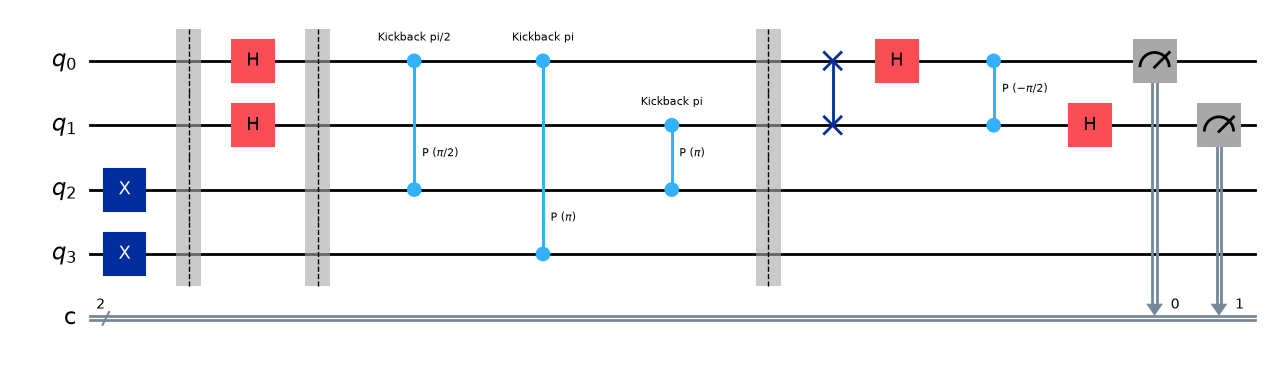

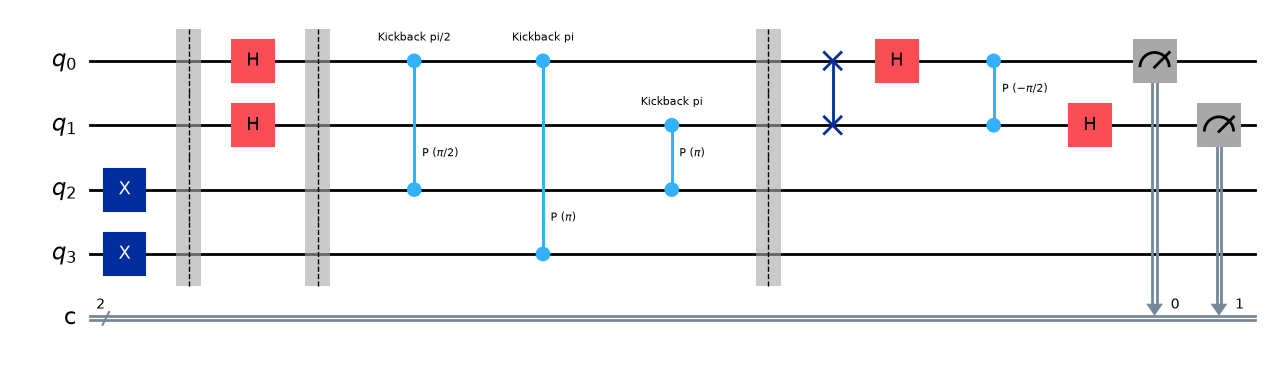

In [6]:
# Required Circuit Diagram: n=2, m=2

qc_diagram = QuantumCircuit(4, 2)

count = [0, 1]
target = [2, 3]

# Step 1: Prepare target state |11>
qc_diagram.x(target[0])
qc_diagram.x(target[1])

qc_diagram.barrier()

# Step 2: Hadamard gates on counting qubits
for k in count:
    qc_diagram.h(k)

qc_diagram.barrier()

# Step 3: Controlled phase kickback gates
# U2 has phase angles:
# Target qubit 0: pi/2
# Target qubit 1: pi

# Counting qubit 0 controls U
qc_diagram.cp(
    np.pi/2, count[0], target[0],
    label="Kickback pi/2"
)

qc_diagram.cp(
    np.pi, count[0], target[1],
    label="Kickback pi"
)

# Counting qubit 1 controls U^2
qc_diagram.cp(
    np.pi, count[1], target[0],
    label="Kickback pi"
)

# The remaining angle is 2*pi, which is an identity operation.
# Therefore, no gate is needed.

qc_diagram.barrier()

# Step 4: Inverse QFT
inverse_qft(qc_diagram, count)

# Step 5: Measurement
for k in count:
    qc_diagram.measure(count[k], k)

# Display circuit diagram
display(qc_diagram.draw(output="mpl", fold=-1))
display(qc_diagram.draw(output="mpl", fold=-1))

-------------------------------------------------------------------------------------------------------------------------------

-------------------------------------------------------------------------------------------------------------------------------

Part A:-

Initial Predictions Before Running.:-

In [7]:
import pandas as pd
predictions = [
    ["A1", 1, "|1>", "0.1", 1, "Yes", "1"],
    ["A2", 1, "|1>", "0.1", 2, "Yes", "10"],
    ["A3", 1, "|1>", "0.1", 3, "Yes", "100"],
    ["A4", 2, "|11>", "0.11", 1, "No", "0 and 1 (tie)"],
    ["A5", 2, "|11>", "0.11", 2, "Yes", "11"],
    ["A6", 2, "|11>", "0.11", 3, "Yes", "110"],
    ["A7", 3, "|101>", "0.101", 1, "No", "1"],
    ["A8", 3, "|101>", "0.101", 2, "No", "10 and 11 (tie)"],
    ["A9", 3, "|101>", "0.101", 3, "Yes", "101"],
    ["A10", 4, "|1011>", "0.1011", 1, "No", "1"],
    ["A11", 4, "|1011>", "0.1011", 2, "No", "11"],
    ["A12", 4, "|1011>", "0.1011", 3, "No", "101 and 110 (tie)"],
    ["A13", 4, "|1000>", "0.1000", 1, "Yes", "1"],
    ["A14", 4, "|1000>", "0.1000", 2, "Yes", "10"],
    ["A15", 4, "|1000>", "0.1000", 3, "Yes", "100"]
]

df_predictions = pd.DataFrame(
    predictions,
    columns=[
        "Run", "n", "Target state", "True phase",
        "m", "Prediction: exact?", "Predicted most likely outcome"
    ]
)

display(df_predictions)


,Run,n,Target state,True phase,m,Prediction: exact?,Predicted most likely outcome
0,A1,1,|1>,0.1,1,Yes,1
1,A2,1,|1>,0.1,2,Yes,10
2,A3,1,|1>,0.1,3,Yes,100
3,A4,2,|11>,0.11,1,No,0 and 1 (tie)
4,A5,2,|11>,0.11,2,Yes,11
5,A6,2,|11>,0.11,3,Yes,110
6,A7,3,|101>,0.101,1,No,1
7,A8,3,|101>,0.101,2,No,10 and 11 (tie)
8,A9,3,|101>,0.101,3,Yes,101
9,A10,4,|1011>,0.1011,1,No,1


After Running and Recording all Results:-

In [8]:

import numpy as np
import matplotlib.pyplot as plt

# Target states for Part A
experiments = [
    (1, 1),    # n=1, x=1
    (2, 3),    # n=2, x=3
    (3, 5),    # n=3, x=5
    (4, 11),   # n=4, x=11
    (4, 8)     # n=4, x=8
]

shots = 2048
results_A = {}

# Run all 15 experiments
for n, x in experiments:

    for m in range(1, 4):

        run_id = f"A{len(results_A) + 1}"

        # Construct QPE circuit
        qc = qpe_circuit(
            build_U(n),
            n,
            m,
            lambda qc, t, x=x: prepare_basis_state(qc, t, x)
        )

        # Run simulation
        counts = run(qc, shots=shots)

        # True phase
        phi = x / (2**n)

        # Most likely outcome
        most_likely = max(counts, key=counts.get)
        y = int(most_likely, 2)

        # Estimated phase
        phi_est = y / (2**m)

        # Measured probability
        measured_prob = counts[most_likely] / shots

        # Theoretical exactness
        exact = np.isclose(phi * (2**m), round(phi * (2**m)))

        # Store results
        results_A[run_id] = {
            "n": n,
            "x": x,
            "m": m,
            "phi": phi,
            "counts": counts,
            "y": y,
            "most_likely": most_likely,
            "phi_est": phi_est,
            "measured_prob": measured_prob,
            "exact": exact
        }

        print(f"\n{run_id}: n={n}, m={m}")
        print("Measurement results:", counts)
        print("Most likely outcome:", most_likely)
        print("Estimated phase:", phi_est)
        print("Probability:", measured_prob)
        print("Exact:", exact)



A1: n=1, m=1
Measurement results: {'1': 2048}
Most likely outcome: 1
Estimated phase: 0.5
Probability: 1.0
Exact: True

A2: n=1, m=2
Measurement results: {'10': 2048}
Most likely outcome: 10
Estimated phase: 0.5
Probability: 1.0
Exact: True

A3: n=1, m=3
Measurement results: {'100': 2048}
Most likely outcome: 100
Estimated phase: 0.5
Probability: 1.0
Exact: True

A4: n=2, m=1
Measurement results: {'1': 1033, '0': 1015}
Most likely outcome: 1
Estimated phase: 0.5
Probability: 0.50439453125
Exact: False

A5: n=2, m=2
Measurement results: {'11': 2048}
Most likely outcome: 11
Estimated phase: 0.75
Probability: 1.0
Exact: True

A6: n=2, m=3
Measurement results: {'110': 2048}
Most likely outcome: 110
Estimated phase: 0.75
Probability: 1.0
Exact: True

A7: n=3, m=1
Measurement results: {'1': 1733, '0': 315}
Most likely outcome: 1
Estimated phase: 0.5
Probability: 0.84619140625
Exact: False

A8: n=3, m=2
Measurement results: {'01': 149, '00': 143, '11': 849, '10': 907}
Most likely outcome: 10

Generating One Histogram per n:-

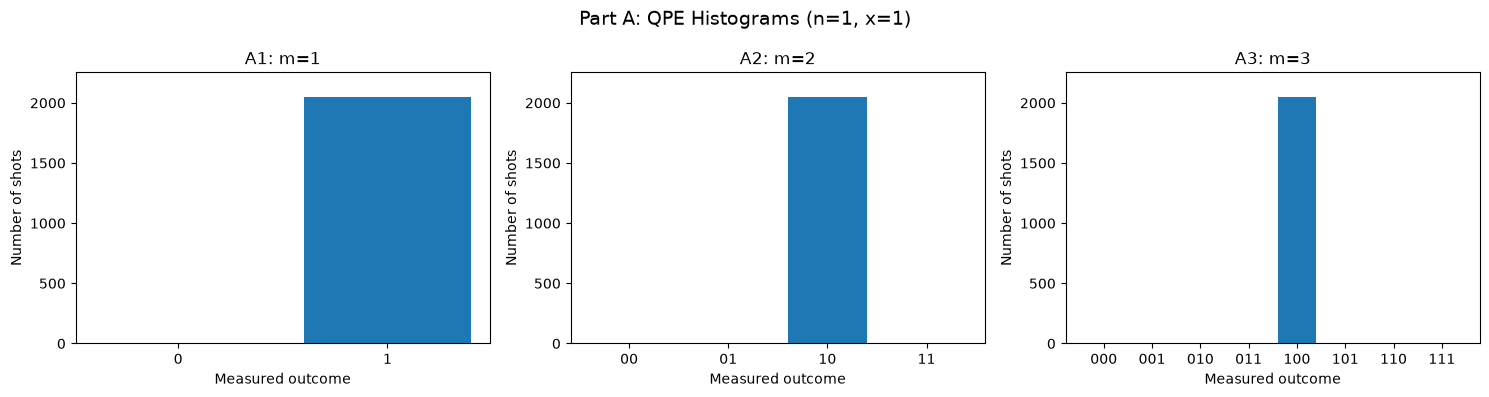

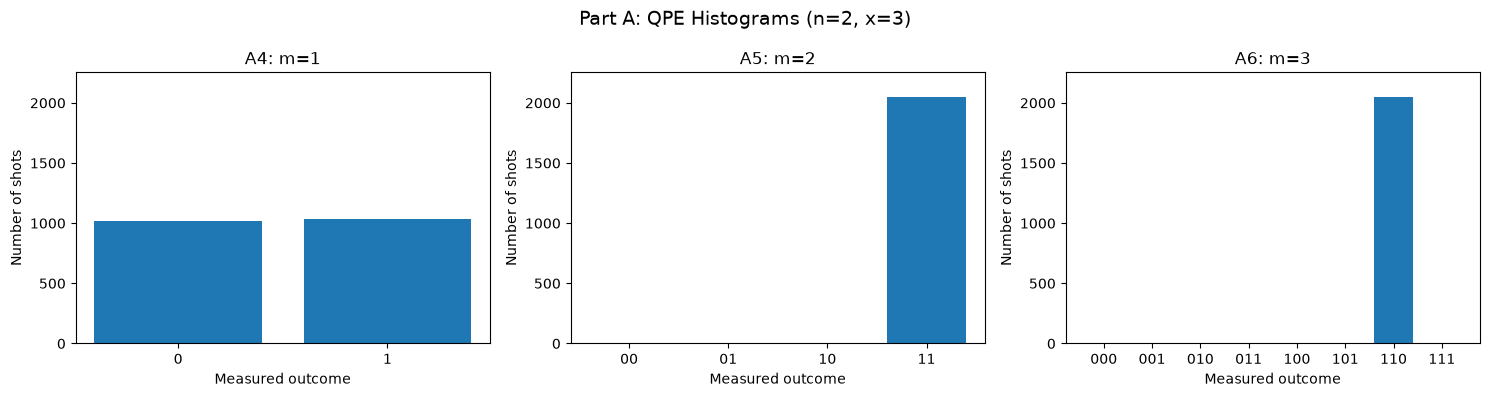

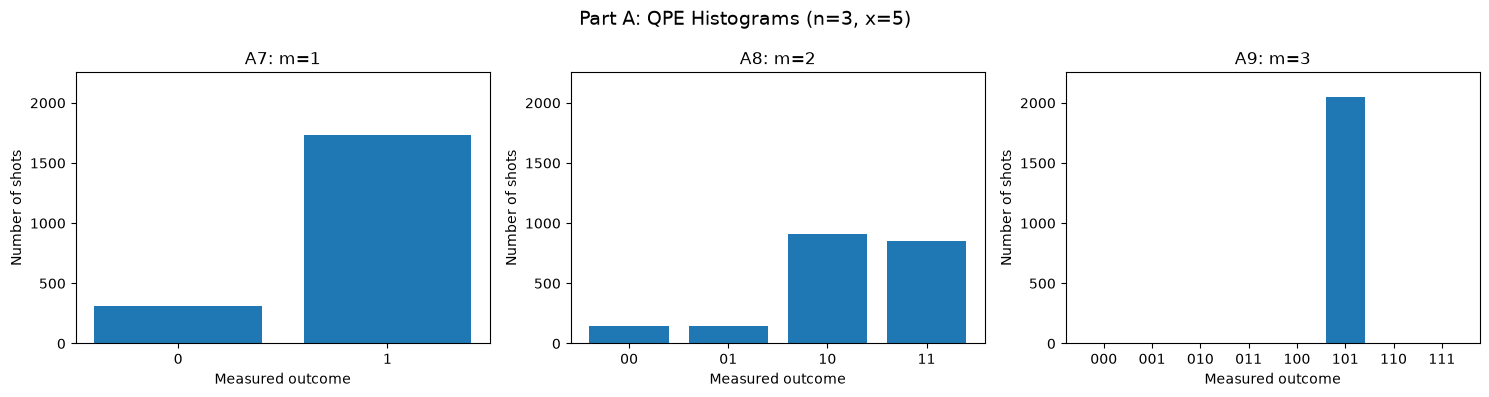

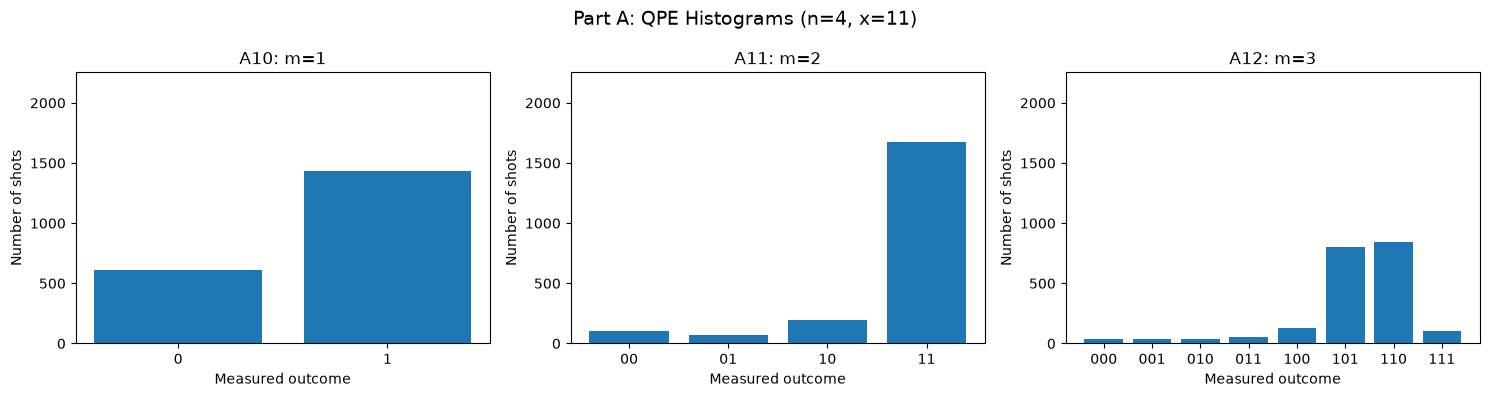

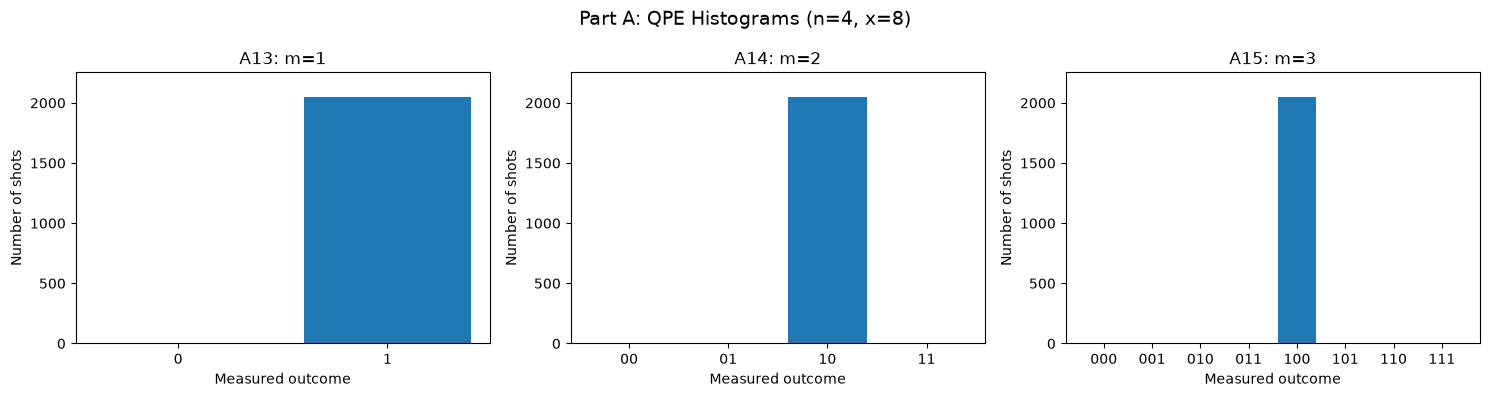

In [9]:

# Generate one figure per target state,
# with m = 1, 2, 3 displayed side by side.

for n, x in experiments:

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for m, ax in zip(range(1, 4), axes):

        run_id = next(
            key for key, value in results_A.items()
            if value["n"] == n
            and value["x"] == x
            and value["m"] == m
        )

        result = results_A[run_id]
        counts = result["counts"]

        # Include all possible outcomes, even if count is zero
        outcomes = [
            format(y, f"0{m}b") for y in range(2**m)
        ]

        frequencies = [
            counts.get(outcome, 0) for outcome in outcomes
        ]

        ax.bar(outcomes, frequencies)
        ax.set_title(f"{run_id}: m={m}")
        ax.set_xlabel("Measured outcome")
        ax.set_ylabel("Number of shots")
        ax.set_ylim(0, shots * 1.1)

    fig.suptitle(
        f"Part A: QPE Histograms (n={n}, x={x})",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


Completed Results Table After Running:-

In [10]:
#Completed table
print(
    f"{'Run':<6} {'n':<3} {'m':<3} "
    f"{'True phase':<12} {'Prediction':<12} "
    f"{'Most likely y':<15} {'Estimated phase':<17} "
    f"{'Measured P':<12} {'Exact?'}"
)

for run_id, r in results_A.items():

    prediction = "Yes" if r["exact"] else "No"

    print(
        f"{run_id:<6} "
        f"{r['n']:<3} "
        f"{r['m']:<3} "
        f"{r['phi']:<12.4f} "
        f"{prediction:<12} "
        f"{r['most_likely']:<15} "
        f"{r['phi_est']:<17.4f} "
        f"{r['measured_prob']:<12.4f} "
        f"{'Yes' if np.isclose(r['phi'], r['phi_est']) else 'No'}"
    )


Run    n   m   True phase   Prediction   Most likely y   Estimated phase   Measured P   Exact?
A1     1   1   0.5000       Yes          1               0.5000            1.0000       Yes
A2     1   2   0.5000       Yes          10              0.5000            1.0000       Yes
A3     1   3   0.5000       Yes          100             0.5000            1.0000       Yes
A4     2   1   0.7500       No           1               0.5000            0.5044       No
A5     2   2   0.7500       Yes          11              0.7500            1.0000       Yes
A6     2   3   0.7500       Yes          110             0.7500            1.0000       Yes
A7     3   1   0.6250       No           1               0.5000            0.8462       No
A8     3   2   0.6250       No           10              0.5000            0.4429       No
A9     3   3   0.6250       Yes          101             0.6250            1.0000       Yes
A10    4   1   0.6875       No           1               0.5000            0.701

Theoretical Probability Comparison:-

In [11]:

def theoretical_probability(phi, m, y):

    N = 2**m

    total = sum(
        np.exp(2j * np.pi * j * (phi - y/N))
        for j in range(N)
    )

    return abs(total / N)**2


# Calculate and compare probabilities for non-exact runs

for run_id, r in results_A.items():

    if r["exact"]:
        continue

    n = r["n"]
    m = r["m"]
    phi = r["phi"]
    counts = r["counts"]

    print(f"\n{run_id}: n={n}, m={m}, true phase={phi:.4f}")
    print("-" * 58)
    print(
        f"{'Outcome y':<12} "
        f"{'P(y) theoretical':<22} "
        f"{'P(y) measured':<18}"
    )

    for y in range(2**m):

        outcome = format(y, f"0{m}b")

        p_theory = theoretical_probability(phi, m, y)
        p_measured = counts.get(outcome, 0) / shots

        print(
            f"{outcome:<12} "
            f"{p_theory:<22.6f} "
            f"{p_measured:<18.6f}"
        )



A4: n=2, m=1, true phase=0.7500
----------------------------------------------------------
Outcome y    P(y) theoretical       P(y) measured     
0            0.500000               0.495605          
1            0.500000               0.504395          

A7: n=3, m=1, true phase=0.6250
----------------------------------------------------------
Outcome y    P(y) theoretical       P(y) measured     
0            0.146447               0.153809          
1            0.853553               0.846191          

A8: n=3, m=2, true phase=0.6250
----------------------------------------------------------
Outcome y    P(y) theoretical       P(y) measured     
00           0.073223               0.069824          
01           0.073223               0.072754          
10           0.426777               0.442871          
11           0.426777               0.414551          

A10: n=4, m=1, true phase=0.6875
----------------------------------------------------------
Outcome y    P(y) theoreti

-------------------------------------------------------------------------------------------------------------------------------

-------------------------------------------------------------------------------------------------------------------------------

Part B:-

Creating the MCP unitary:-

In [12]:
def build_MCP(n):
    """Build MCP(2*pi/3) on n target qubits."""

    theta = 2 * np.pi / 3

    qc = QuantumCircuit(n, name=f"MCP{n}")

    if n == 1:
        qc.p(theta, 0)
    else:
        qc.mcp(theta, list(range(n-1)), n-1)

    return qc


Building the Circuit:-

In [13]:

def qpe_circuit_B(n, m):

    qc = QuantumCircuit(m + n, m)

    count = list(range(m))
    target = list(range(m, m+n))

    # Prepare all-ones target state
    for q in target:
        qc.x(q)

    # Hadamards on counting register
    for k in range(m):
        qc.h(count[k])

    theta = 2 * np.pi / 3

    # Controlled powers of MCP
    for k in range(m):

        angle = (2**k) * theta

        if n == 1:
            qc.cp(angle, count[k], target[0])
        else:
            controls = [count[k]] + target[:-1]
            qc.mcp(angle, controls, target[-1])

    # Inverse QFT
    inverse_qft(qc, count)

    # Measurement
    for k in range(m):
        qc.measure(count[k], k)

    return qc


Running All Experiments:-

In [14]:
import numpy as np
import matplotlib.pyplot as plt

shots = 2048
results_B = {}

# Run B1-B12
for n in range(1, 5):

    for m in range(1, 4):

        run_id = f"B{(n-1)*3 + m}"

        # Construct and run QPE circuit
        qc = qpe_circuit_B(n, m)
        counts = run(qc, shots=shots)

        # True phase
        phi = 1/3

        # Sort outcomes by measurement frequency
        sorted_outcomes = sorted(
            counts.items(),
            key=lambda item: item[1],
            reverse=True
        )

        # Two most likely outcomes
        top_two = sorted_outcomes[:2]

        most_likely = top_two[0][0]
        second_likely = top_two[1][0]

        y = int(most_likely, 2)

        # Estimated phase and error
        phi_est = y / (2**m)
        error = abs(phi - phi_est)

        # Theoretical error bound
        error_bound = 1 / (2**(m+1))

        results_B[run_id] = {
            "n": n,
            "m": m,
            "phi": phi,
            "counts": counts,
            "top_two": top_two,
            "most_likely": most_likely,
            "second_likely": second_likely,
            "phi_est": phi_est,
            "error": error,
            "error_bound": error_bound,
            "bound_satisfied": error <= error_bound
        }

        print(f"\n{run_id}: n={n}, m={m}")
        print("All measurement results:", counts)
        print("Two most likely outcomes:")

        for outcome, count in top_two:
            print(
                outcome,
                "| Probability:",
                round(count/shots, 4)
            )

        print("Estimated phase:", round(phi_est, 6))
        print("Absolute error:", round(error, 6))
        print("Error bound:", round(error_bound, 6))
        print("Bound satisfied:", error <= error_bound)


# Generate the Part B results table
print("\n\nPART B - SUMMARY TABLE")
print("-" * 105)

print(
    f"{'Run':<6} {'n':<4} {'m':<4} "
    f"{'Most likely':<14} {'P1':<10} "
    f"{'Second likely':<15} {'P2':<10} "
    f"{'Estimate':<12} {'Error':<12} {'Bound?'}"
)

for run_id, r in results_B.items():

    outcome1, count1 = r["top_two"][0]
    outcome2, count2 = r["top_two"][1]

    print(
        f"{run_id:<6} "
        f"{r['n']:<4} "
        f"{r['m']:<4} "
        f"{outcome1:<14} "
        f"{count1/shots:<10.4f} "
        f"{outcome2:<15} "
        f"{count2/shots:<10.4f} "
        f"{r['phi_est']:<12.4f} "
        f"{r['error']:<12.4f} "
        f"{'Yes' if r['bound_satisfied'] else 'No'}"
    )




B1: n=1, m=1
All measurement results: {'0': 533, '1': 1515}
Two most likely outcomes:
1 | Probability: 0.7397
0 | Probability: 0.2603
Estimated phase: 0.5
Absolute error: 0.166667
Error bound: 0.25
Bound satisfied: True

B2: n=1, m=2
All measurement results: {'11': 95, '00': 130, '10': 378, '01': 1445}
Two most likely outcomes:
01 | Probability: 0.7056
10 | Probability: 0.1846
Estimated phase: 0.25
Absolute error: 0.083333
Error bound: 0.125
Bound satisfied: True

B3: n=1, m=3
All measurement results: {'101': 39, '110': 20, '001': 71, '100': 85, '111': 24, '011': 1422, '000': 28, '010': 359}
Two most likely outcomes:
011 | Probability: 0.6943
010 | Probability: 0.1753
Estimated phase: 0.375
Absolute error: 0.041667
Error bound: 0.0625
Bound satisfied: True

B4: n=2, m=1
All measurement results: {'0': 505, '1': 1543}
Two most likely outcomes:
1 | Probability: 0.7534
0 | Probability: 0.2466
Estimated phase: 0.5
Absolute error: 0.166667
Error bound: 0.25
Bound satisfied: True

B5: n=2, m

Generating Histograms:-

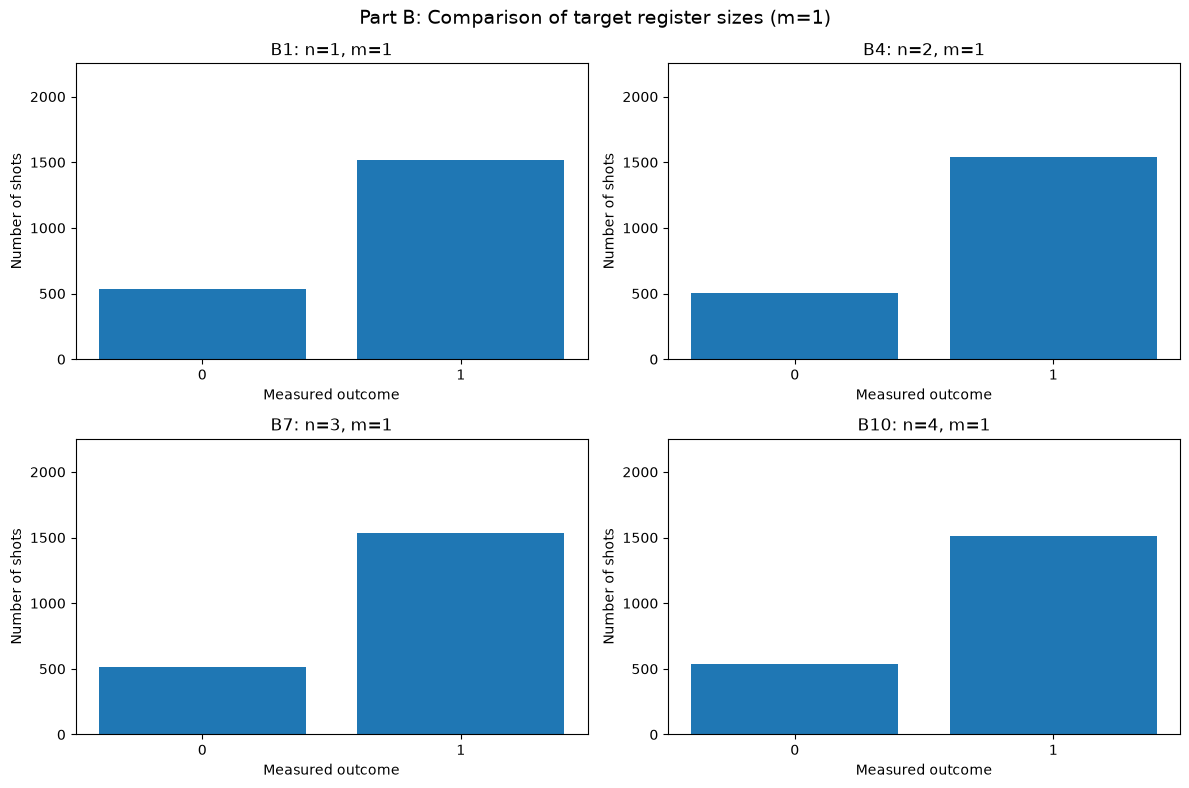

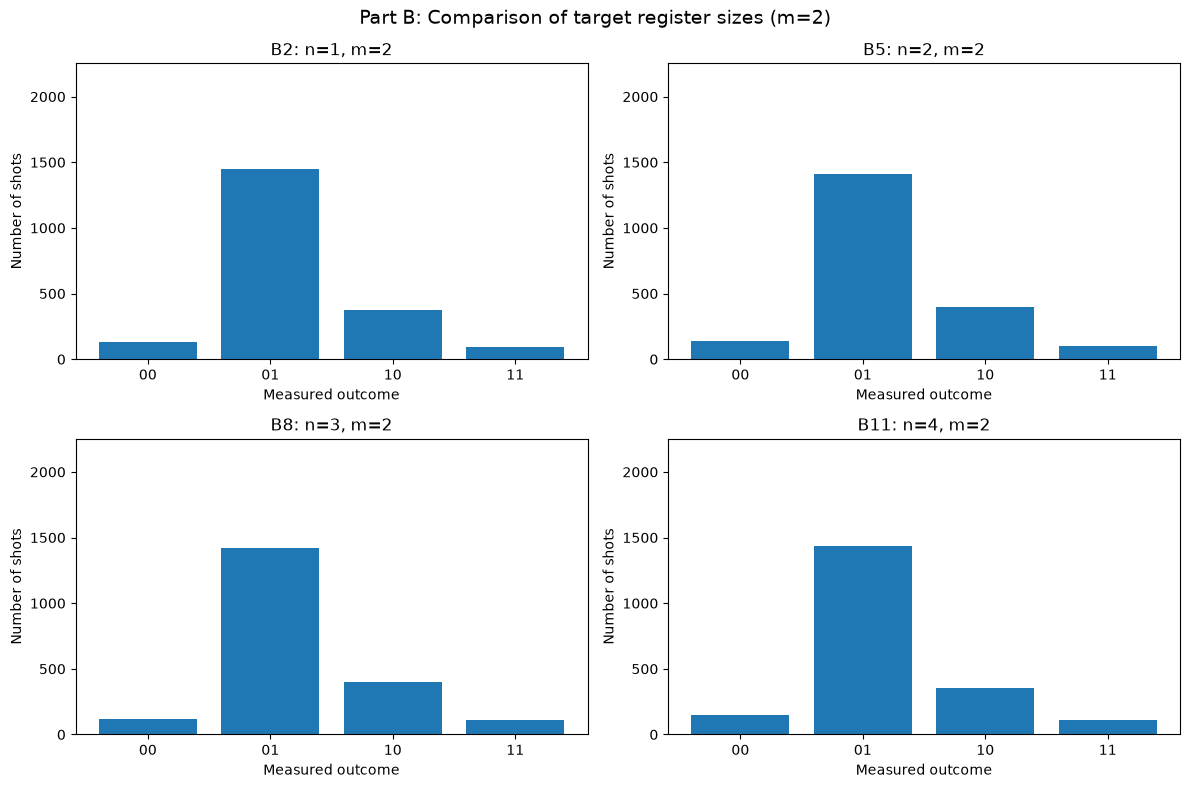

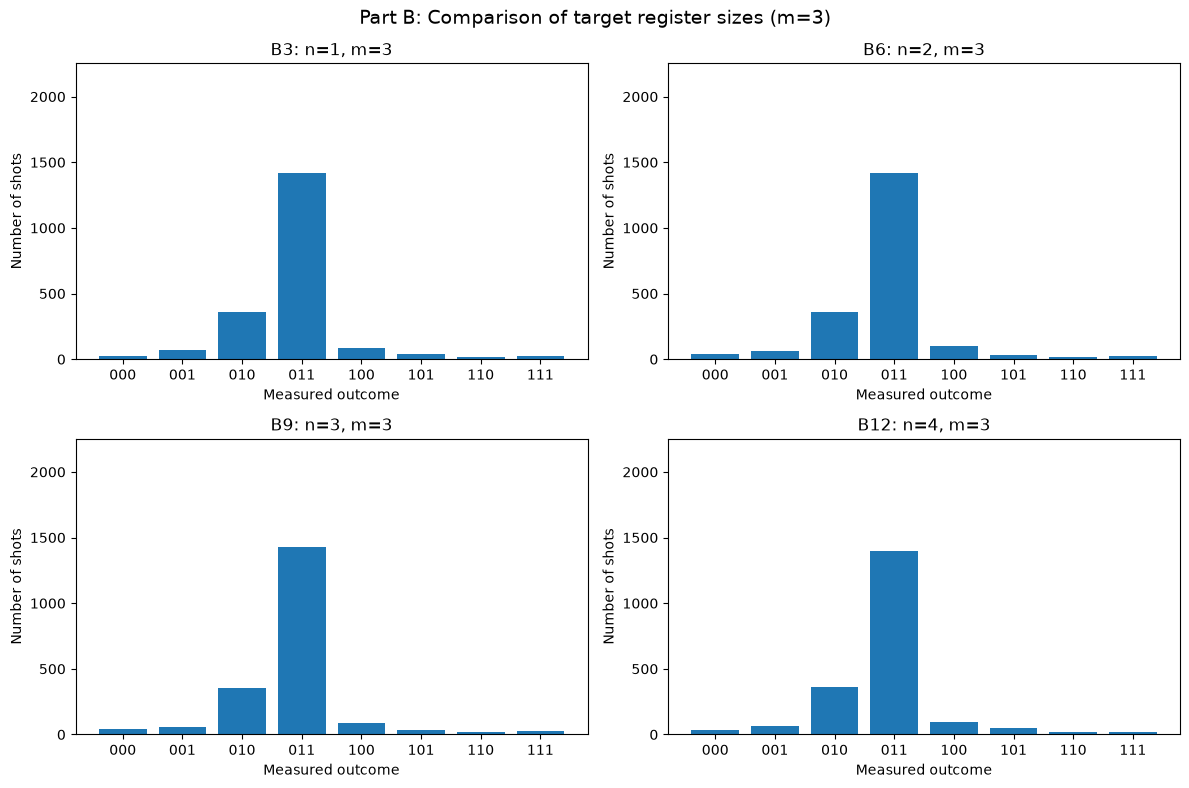

In [15]:

for m in range(1, 4):

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes = axes.flatten()

    for n, ax in zip(range(1, 5), axes):

        run_id = f"B{(n-1)*3 + m}"
        counts = results_B[run_id]["counts"]

        outcomes = [
            format(y, f"0{m}b")
            for y in range(2**m)
        ]

        frequencies = [
            counts.get(outcome, 0)
            for outcome in outcomes
        ]

        ax.bar(outcomes, frequencies)
        ax.set_title(f"{run_id}: n={n}, m={m}")
        ax.set_xlabel("Measured outcome")
        ax.set_ylabel("Number of shots")
        ax.set_ylim(0, shots * 1.1)

    fig.suptitle(
        f"Part B: Comparison of target register sizes (m={m})",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


Additional experiment: n = 4, |v⟩ = |1110⟩, m = 3

### Prediction

For n = 4, m = 3 and target state |1110⟩, the multi-controlled phase condition is not satisfied because the target register is not in the all-ones state.

Therefore, the unitary does not introduce any phase, and the true eigenphase is φ = 0.

It is predicted that the QPE will return the outcome `000` with probability 1.

In [16]:

# Additional Part B experiment
# n = 4, |v> = |1110>, m = 3

def qpe_circuit_B_extra(n, m, x):

    qc = QuantumCircuit(m+n, m)

    count = list(range(m))
    target = list(range(m, m+n))

    # Prepare |1110> (x = 14)
    prepare_basis_state(qc, target, x)

    # Hadamards on counting register
    for k in range(m):
        qc.h(count[k])

    theta = 2 * np.pi / 3

    # Controlled powers of MCP
    for k in range(m):

        angle = (2**k) * theta

        controls = [count[k]] + target[:-1]
        qc.mcp(angle, controls, target[-1])

    # Inverse QFT
    inverse_qft(qc, count)

    # Measurements
    for k in range(m):
        qc.measure(count[k], k)

    return qc


# Run the additional experiment
qc_B_extra = qpe_circuit_B_extra(4, 3, 14)

counts_B_extra = run(qc_B_extra, shots=shots)

print("Additional experiment: n=4, m=3, |v>=|1110>")
print("Measurement results:", counts_B_extra)


Additional experiment: n=4, m=3, |v>=|1110>
Measurement results: {'000': 2048}


### Part B – Histogram Comparison and Observations

For a fixed number of counting qubits m, the probability distributions are expected to remain the same for all four values of n.

This is because the phase of the all-ones target state remains φ = 1/3, independently of the number of target qubits.

The histograms therefore demonstrate that changing the target-register size does not change the estimated phase distribution when the eigenphase remains unchanged.

Increasing m changes the distribution by providing greater precision in the phase estimate. However, since 1/3 has a non-terminating binary expansion, exact estimation is not possible for any of the finite values of m used in these experiments.

The most likely outcome satisfies the theoretical error bound in the experiments.

-------------------------------------------------------------------------------------------------------------------------------

-------------------------------------------------------------------------------------------------------------------------------

Part C:- When |v> is not an eigenstate:-

In [17]:
# Setup for Part C
U_X = QuantumCircuit(1, name="X")
U_X.x(0)

U_2 = build_U(2)

def prep_minus(qc, target):
    qc.x(target[0])
    qc.h(target[0])

def prep_plus(qc, target):
    qc.h(target[0])

def prep_zero(qc, target):
    pass  # Initialized in |0> by default

def prep_plus_plus(qc, target):
    qc.h(target[0])
    qc.h(target[1])

runs_C = {
    "C1 (U=X, |v>=|->, m=2)": qpe_circuit(U_X, 1, 2, prep_minus),
    "C2 (U=X, |v>=|+>, m=2)": qpe_circuit(U_X, 1, 2, prep_plus),
    "C3 (U=X, |v>=|0>, m=2)": qpe_circuit(U_X, 1, 2, prep_zero),
    "C4 (U=U_2, |v>=|++>, m=2)": qpe_circuit(U_2, 2, 2, prep_plus_plus),
    "C5 (U=U_2, |v>=|++>, m=1)": qpe_circuit(U_2, 2, 1, prep_plus_plus)
}

print("Part C: When |v> is not an eigenstate\n" + "-"*40)
for name, qc in runs_C.items():
    print(f"{name}:")
    counts = run(qc)
    print("Measurement results:", counts)
    for outcome, count in counts.items():
        print(f"Probability of {outcome}: {count / 2048:.4f}")
    print("-" * 40)

Part C: When |v> is not an eigenstate
----------------------------------------
C1 (U=X, |v>=|->, m=2):
Measurement results: {'10': 2048}
Probability of 10: 1.0000
----------------------------------------
C2 (U=X, |v>=|+>, m=2):
Measurement results: {'00': 2048}
Probability of 00: 1.0000
----------------------------------------
C3 (U=X, |v>=|0>, m=2):
Measurement results: {'10': 1053, '00': 995}
Probability of 10: 0.5142
Probability of 00: 0.4858
----------------------------------------
C4 (U=U_2, |v>=|++>, m=2):
Measurement results: {'00': 503, '11': 514, '10': 506, '01': 525}
Probability of 00: 0.2456
Probability of 11: 0.2510
Probability of 10: 0.2471
Probability of 01: 0.2563
----------------------------------------
C5 (U=U_2, |v>=|++>, m=1):
Measurement results: {'0': 1040, '1': 1008}
Probability of 0: 0.5078
Probability of 1: 0.4922
----------------------------------------


In [18]:
#Target Collapse Demonstration
def qpe_circuit_C4_target(U, n, m, prepare):
    # Create m+n classical bits to measure both registers
    qc = QuantumCircuit(m + n, m + n)
    count = list(range(m))
    target = list(range(m, m + n))
    
    prepare(qc, target)
    
    for k in range(m):
        qc.h(count[k])
        
    controlled_U = U.to_gate().control(1)
    for k in range(m):
        for _ in range(2**k):
            qc.append(controlled_U, [count[k]] + target)
            
    inverse_qft(qc, count)
    
    # Measure counting register (bits 0 to m-1)
    for k in range(m):
        qc.measure(count[k], k)
        
    # Measure target register (bits m to m+n-1)
    for j in range(n):
        qc.measure(target[j], m + j)
        
    return qc

qc_C4_target = qpe_circuit_C4_target(U_2, 2, 2, prep_plus_plus)
counts_C4_target = run(qc_C4_target)

print("C4 Joint Outcomes (Target Bits + Counting Bits):")
for outcome, count in counts_C4_target.items():
    # Qiskit strings are read right-to-left (Target bits are on the left, Count bits on the right)
    target_bits = outcome[:2]
    count_bits = outcome[2:]
    print(f"y (counting) = {count_bits}, target state = |{target_bits}> : Probability = {count/2048:.4f}")

C4 Joint Outcomes (Target Bits + Counting Bits):
y (counting) = 11, target state = |11> : Probability = 0.2593
y (counting) = 10, target state = |10> : Probability = 0.2695
y (counting) = 01, target state = |01> : Probability = 0.2305
y (counting) = 00, target state = |00> : Probability = 0.2407


### Part C – Results and Observations

The results of the five experiments are summarized below.

| Run | Target state | Expected phase(s) | Observed outcomes | Observed probabilities |
|---|---|---|---|---|
| C1 | \(|-\rangle\) | \(1/2\) | `10` | 1.0000 |
| C2 | \(|+\rangle\) | \(0\) | `00` | 1.0000 |
| C3 | \(|0\rangle\) | \(0,\ 1/2\) | `00`, `10` | 0.4858, 0.5142 |
| C4 | \(|++\rangle\) | \(0,\ 1/4,\ 1/2,\ 3/4\) | `00`, `01`, `10`, `11` | Approximately 0.25 each |
| C5 | \(|++\rangle\) | \(0,\ 1/4,\ 1/2,\ 3/4\) | `0`, `1` | 0.5078, 0.4922 |

### C1 and C2 – Eigenstates of X

The Pauli-X operator has two eigenstates:

\[
X|+\rangle=|+\rangle
\]

\[
X|-\rangle=-|-\rangle=e^{2\pi i(1/2)}|-\rangle
\]

Therefore, the corresponding eigenphases are 0 and 1/2.

Since both target states are eigenstates, QPE produces deterministic results. C1 returns `10`, representing \(1/2\), while C2 returns `00`, representing 0.

### C3 – Target state is not an eigenstate

The computational basis state \(|0\rangle\) is not an eigenstate of X. It can be expressed as a superposition of the two eigenstates:

\[
|0\rangle=\frac{|+\rangle+|-\rangle}{\sqrt{2}}
\]

QPE acts independently on these two eigenstate components.

- The component \(|+\rangle\) has phase 0 and produces `00`.
- The component \(|-\rangle\) has phase \(1/2\) and produces `10`.

Since both components have equal amplitudes, their measurement probabilities are each 1/2. The observed probabilities are approximately equal, as expected.

### C4 – Superposition of four eigenstates

For \(U_2\), the computational basis states are eigenstates with phases determined by \(x/4\).

The target state can be expanded as:

\[
|++\rangle=\frac{1}{2}
\left(
|00\rangle+|01\rangle+|10\rangle+|11\rangle
\right)
\]

The corresponding eigenphases are:

| Eigenstate | Eigenphase | QPE outcome |
|---|---|---|
| \(|00\rangle\) | 0 | `00` |
| \(|01\rangle\) | 1/4 | `01` |
| \(|10\rangle\) | 1/2 | `10` |
| \(|11\rangle\) | 3/4 | `11` |

Each eigenstate has an amplitude of 1/2, giving it a probability of 1/4.

The joint measurement of the counting and target registers confirms this relationship:

| Counting outcome | Target state | Observed probability |
|---|---|---|
| `00` | \(|00\rangle\) | 0.2407 |
| `01` | \(|01\rangle\) | 0.2305 |
| `10` | \(|10\rangle\) | 0.2695 |
| `11` | \(|11\rangle\) | 0.2593 |

The target register collapses to the eigenstate corresponding to the measured phase. The small differences from 0.25 are due to finite sampling.

### C5 – Insufficient counting qubits

C5 uses the same target state as C4, but only one counting qubit.

There are four possible eigenphases, but one counting qubit can distinguish only two outcomes: `0` and `1`.

Consequently, it cannot uniquely identify all four eigenphases. The contributions from the four eigenstate components combine into an approximately equal probability distribution between the two possible outcomes.

The observed probabilities, 0.5078 and 0.4922, are close to the expected 0.5 each.

### Conclusion

Part C demonstrates that QPE can process a target state that is not an eigenstate, but the result is a probability distribution over the eigenphases of the unitary. The probability associated with each eigenphase is determined by the squared magnitude of the corresponding eigenstate's amplitude in the target-state decomposition.

It also demonstrates that the number of counting qubits determines how many phase values can be distinguished. In C5, one counting qubit is insufficient to distinguish four different eigenphases.

-------------------------------------------------------------------------------------------------------------------------------

-------------------------------------------------------------------------------------------------------------------------------
Part D:-

Diagnose broken circuits:-

In [19]:
# Setup
U_3 = build_U(3)

def prep_101(qc, target):
    prepare_basis_state(qc, target, 5)

# Broken QFT implementations
def inverse_qft_no_swap(qc, qubits):
    m = len(qubits)
    for j in range(m):
        for k in range(j):
            qc.cp(-np.pi / 2**(j - k), qubits[k], qubits[j])
        qc.h(qubits[j])

def forward_qft(qc, qubits):
    m = len(qubits)
    for j in reversed(range(m)):
        qc.h(qubits[j])
        for k in reversed(range(j)):
            qc.cp(np.pi / 2**(j - k), qubits[k], qubits[j])
    for i in range(m // 2):
        qc.swap(qubits[i], qubits[m - 1 - i])

# Buggy QPE logic wrapper
def qpe_buggy(U, n, m, prepare, bug=None):
    qc = QuantumCircuit(m + n, m)
    count = list(range(m))
    target = list(range(m, m + n))
    
    prepare(qc, target)
    
    # D4: Missing H gates
    if bug != 'D4':
        for i in count:
            qc.h(i)
            
    cU = U.to_gate().control(1)
    for k in count:
        if bug == 'D1':
            powers = 1 # D1: controls U only once
        elif bug == 'D3':
            powers = 2**(m - 1 - k) # D3: reversed powers
        else:
            powers = 2**k
            
        for _ in range(powers):
            qc.append(cU, [count[k]] + target)
            
    if bug == 'D2':
        inverse_qft_no_swap(qc, count) # D2: No swaps
    elif bug == 'D5':
        forward_qft(qc, count) # D5: Forward QFT instead of Inverse
    else:
        inverse_qft(qc, count)
        
    for k in range(m):
        qc.measure(count[k], k)
    return qc

In [9]:
# D6 Preparation: Reversing bit order for x=3 (011 reversed)
def prep_D6_reversed(qc, target):
    x = 3 
    n = len(target)
    for j, q in enumerate(target):
        if (x >> (n - 1 - j)) & 1: 
            qc.x(q)

runs_D = {
    "D1 (No Powers)": qpe_buggy(U_3, 3, 3, prep_101, 'D1'),
    "D2 (No Swaps)": qpe_buggy(U_3, 3, 3, prep_101, 'D2'),
    "D3 (Reversed Powers)": qpe_buggy(U_3, 3, 3, prep_101, 'D3'),
    "D4 (No H Gates)": qpe_buggy(U_3, 3, 3, prep_101, 'D4'),
    "D5 (Forward QFT)": qpe_buggy(U_3, 3, 3, prep_101, 'D5'),
    "D6 (Reversed X Prep)": qpe_circuit(U_3, 3, 3, prep_D6_reversed)
}

print("Part D: Broken Circuits Diagnostics\n" + "-"*40)
for name, qc in runs_D.items():
    counts = run(qc)
    print(f"{name}:")
    print("Measurement results:", counts)
    print("-" * 40)

NameError: name 'qpe_buggy' is not defined

Combining D2 and D3:-

In [21]:

# D2+D3 (No swaps+Reversed powers)

def qpe_combined_bug(U, n, m, prepare):

    qc = QuantumCircuit(m+n, m)

    count = list(range(m))
    target = list(range(m, m+n))

    prepare(qc, target)

    # Hadamards
    for k in range(m):
        qc.h(count[k])

    # Reversed powers
    for k in range(m):
        controlled_U = U.to_gate().control(1)

        for _ in range(2**(m-1-k)):
            qc.append(controlled_U, [count[k]] + target)

    # Inverse QFT WITHOUT swaps
    for j in range(m):
        for k in range(j):
            qc.cp(-np.pi / 2**(j-k), count[k], count[j])
        qc.h(count[j])

    # Measurements
    for k in range(m):
        qc.measure(count[k], k)

    return qc


qc_D2_D3 = qpe_combined_bug(
    build_U(3),
    3,
    3,
    lambda qc, t: prepare_basis_state(qc, t, 5)
)

counts_D2_D3 = run(qc_D2_D3)

print("D2 + D3 combined results:", counts_D2_D3)


D2 + D3 combined results: {'101': 2048}


Histograms:-

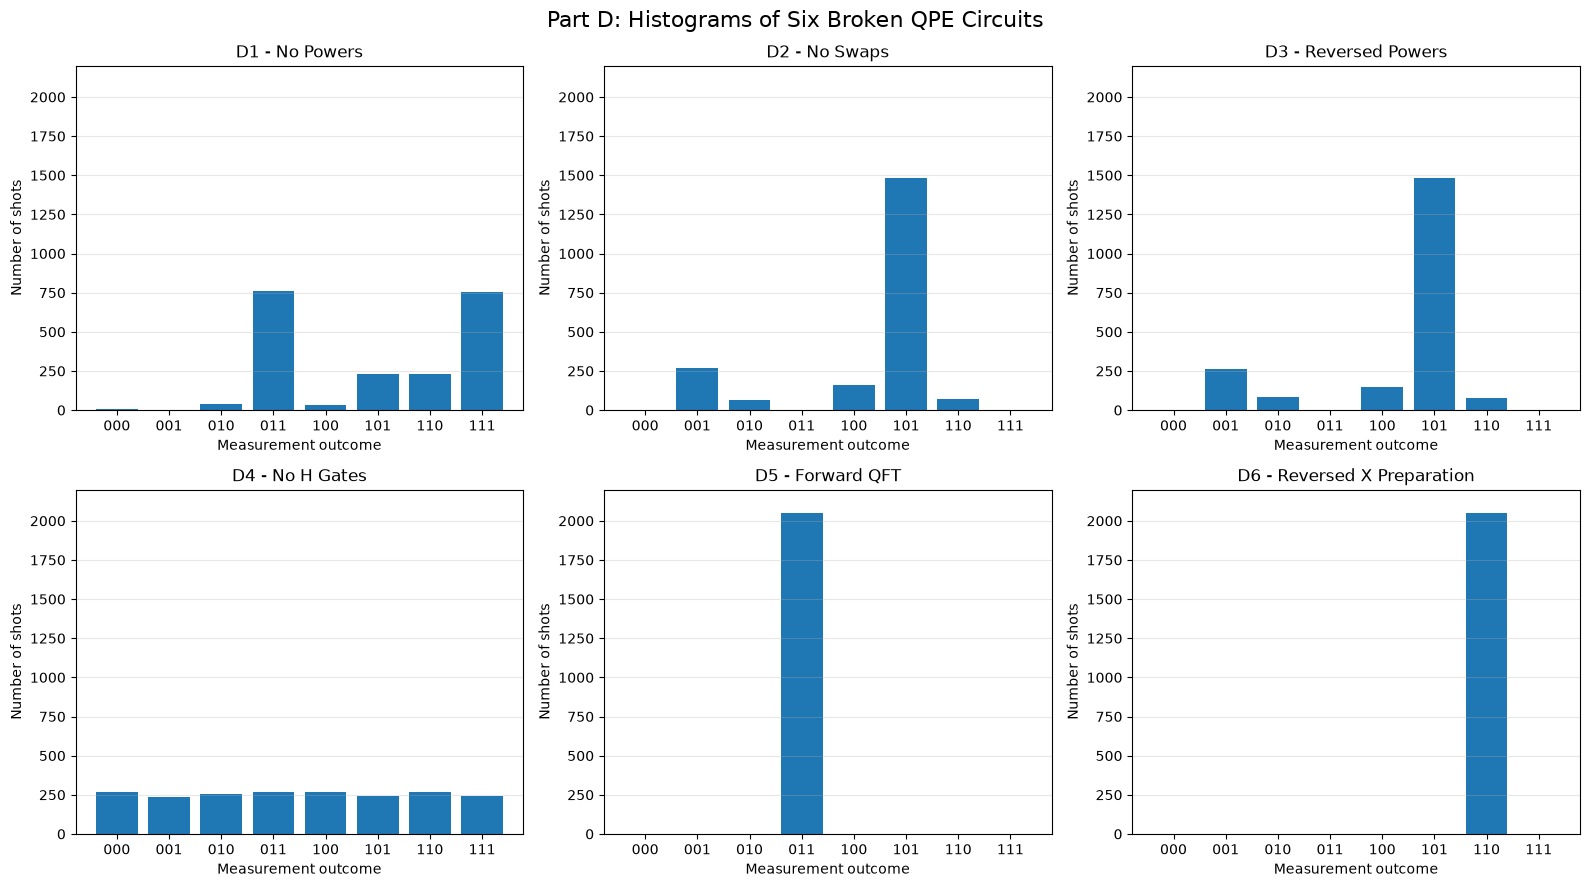

In [22]:

import matplotlib.pyplot as plt

# Actual measurement results from Part D
results_D = {
    "D1 - No Powers": {
        '000': 4, '010': 38, '110': 228, '100': 35,
        '111': 753, '011': 759, '101': 231
    },

    "D2 - No Swaps": {
        '001': 269, '100': 158, '010': 65,
        '110': 71, '101': 1485
    },

    "D3 - Reversed Powers": {
        '100': 146, '001': 262, '010': 82,
        '110': 78, '101': 1480
    },

    "D4 - No H Gates": {
        '101': 244, '100': 268, '001': 236,
        '110': 271, '111': 240, '011': 266,
        '000': 268, '010': 255
    },

    "D5 - Forward QFT": {
        '011': 2048
    },

    "D6 - Reversed X Preparation": {
        '110': 2048
    }
}

# All possible 3-bit measurement outcomes
outcomes = [format(i, '03b') for i in range(8)]

# Generate six histograms
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, (name, counts) in zip(axes, results_D.items()):

    frequencies = [counts.get(outcome, 0) for outcome in outcomes]

    ax.bar(outcomes, frequencies)

    ax.set_title(name)
    ax.set_xlabel("Measurement outcome")
    ax.set_ylabel("Number of shots")
    ax.set_ylim(0, 2200)
    ax.grid(axis='y', alpha=0.3)

fig.suptitle(
    "Part D: Histograms of Six Broken QPE Circuits",
    fontsize=16
)

plt.tight_layout()
plt.show()


Mathematical explanations:-


### Mathematical Analysis of Broken Circuits

The correct QPE circuit uses the target state |101>, with the unitary U_3 and three counting qubits.

The corresponding eigenphase is:

phi = 5/8 = 0.101_2

Therefore, the correct QPE circuit should produce the measurement outcome 101 with probability 1.

### D1 – No Powers

In the correct implementation, counting qubit k controls U^(2^k).

For three counting qubits, the controlled operations should be:

- Counting qubit 0: U
- Counting qubit 1: U^2
- Counting qubit 2: U^4

Without applying the powers, every counting qubit controls only U.

Consequently, each counting qubit acquires the same phase instead of acquiring the phase corresponding to its binary position.

The counting register is therefore not prepared in the correct phase-encoded state, and the inverse QFT cannot recover the correct binary representation of the phase.

This produces a spread-out measurement distribution instead of the expected deterministic outcome 101.

### D2 – No Swaps

The inverse QFT requires swap gates to reverse the order of the counting qubits.

These swaps ensure that the output bits correspond to the correct binary positions.

Removing the swaps changes the bit ordering of the inverse QFT output. Consequently, the measurement outcomes no longer follow the intended binary representation of the estimated phase.

In this experiment, 101 remains the most frequent outcome because it is a palindrome and is unchanged by bit reversal. However, the remaining measurement distribution demonstrates that the modified circuit does not produce the ideal result.

### D3 – Reversed Powers

The correct assignment of powers is:

U^(1), U^(2), U^(4)

In this experiment, the powers are assigned in reverse order:

U^(4), U^(2), U^(1)

This reverses the relationship between the counting qubits and the binary positions of the phase.

As a result, the phase information is encoded in the wrong order, preventing the inverse QFT from correctly interpreting the counting register.

The outcome 101 remains the most frequent because reversing its bits produces the same bitstring. However, the other outcomes show that the measurement distribution is affected.

### D4 – No Hadamard Gates

The Hadamard gates are necessary to create an equal superposition in the counting register.

For each counting qubit:

H|0> = (|0> + |1>)/sqrt(2)

Without these gates, the counting register remains in the state |000>.

Since the counting qubits are never placed in a superposition, phase kickback cannot encode the eigenphase into the counting register.

The inverse QFT then transforms |000> into an equal superposition of all eight possible three-bit outcomes.

Therefore, the theoretical probability of each outcome is:

P(y) = 1/8 = 0.125

The measured histogram is approximately uniform, confirming the effect of removing the Hadamard gates.

### D5 – Forward QFT Instead of Inverse QFT

The correct QPE procedure uses the inverse QFT to extract the phase encoded by the controlled-unitary operations.

The inverse QFT uses negative phase rotations, whereas the forward QFT uses positive phase rotations.

Using the forward QFT instead effectively changes the estimated phase from phi to:

phi' = -phi mod 1

For the original phase:

phi = 5/8

Therefore:

phi' = -5/8 mod 1
     = 3/8
     = 0.011_2

Hence, the circuit deterministically produces the outcome 011 instead of 101.

This matches the simulation result.

### D6 – Reversed X Preparation

The correct target state is:

|v> = |101>

Its corresponding eigenphase is:

phi = 5/8 = 0.101_2

Reversing the X gate preparation changes the target state to:

|v> = |110>

The new target state corresponds to the integer 6 instead of 5.

Therefore, its eigenphase becomes:

phi' = 6/8
     = 3/4
     = 0.110_2

Since the QPE circuit itself remains correct, it successfully estimates this new phase and produces the outcome 110 with probability 1.

This demonstrates that incorrect state preparation can produce an incorrect phase estimate even when the QPE implementation is otherwise correct.

### Overall Conclusion

The six experiments demonstrate how different implementation mistakes affect quantum phase estimation.

Incorrect controlled powers, missing swaps and reversed powers affect the encoding or ordering of phase information. Removing Hadamard gates prevents phase kickback, while using the forward QFT reverses the sign of the estimated phase.

Finally, reversing the target-state preparation changes the eigenstate being measured, resulting in a different but correctly estimated eigenphase.


-------------------------------------------------------------------------------------------------------------------------------
Optional bonus (+10):-
Noisy simulator comparison:-

In [24]:
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

fake_backend = FakeManilaV2()

# QPE constructed using O(1) angle multiplication
def qpe_angle_mult(n, m, prepare):
    qc = QuantumCircuit(m + n, m)
    count = list(range(m))
    target = list(range(m, m + n))
    
    prepare(qc, target)
    
    for i in count:
        qc.h(i)
        
    # Apply U^(2^k) by multiplying phase angles rather than repeating gates
    for k in count:
        for j in range(n):
            theta = 2 * np.pi * (2**j) / (2**n)
            scaled_angle = theta * (2**k)
            qc.cp(scaled_angle, count[k], target[j])
            
    inverse_qft(qc, count)
    
    for k in range(m):
        qc.measure(count[k], k)
        
    return qc

def run_noisy(qc, shots=2048):
    transpiled = transpile(qc, fake_backend)
    return fake_backend.run(transpiled, shots=shots).result().get_counts()

ModuleNotFoundError: No module named 'qiskit_ibm_runtime'

In [25]:
def prep_1011(qc, target):
    prepare_basis_state(qc, target, 11)

U_4 = build_U(4)

print("Running Noisy Simulations (This may take a moment...)\n" + "-"*50)

# A9 Execution (n=3, m=3, v=101)
qc_A9_rep = qpe_circuit(U_3, 3, 3, prep_101)
qc_A9_angle = qpe_angle_mult(3, 3, prep_101)

print("A9 (Noisy - Repetition Method Depth):", transpile(qc_A9_rep, fake_backend).depth())
print("A9 (Noisy - Repetition Method Counts):", run_noisy(qc_A9_rep))
print("A9 (Noisy - Angle Method Depth):", transpile(qc_A9_angle, fake_backend).depth())
print("A9 (Noisy - Angle Method Counts):", run_noisy(qc_A9_angle))
print("-" * 50)

# A12 Execution (n=4, m=3, v=1011)
qc_A12_rep = qpe_circuit(U_4, 4, 3, prep_1011)
qc_A12_angle = qpe_angle_mult(4, 3, prep_1011)

print("A12 (Noisy - Repetition Method Depth):", transpile(qc_A12_rep, fake_backend).depth())
print("A12 (Noisy - Repetition Method Counts):", run_noisy(qc_A12_rep))
print("A12 (Noisy - Angle Method Depth):", transpile(qc_A12_angle, fake_backend).depth())
print("A12 (Noisy - Angle Method Counts):", run_noisy(qc_A12_angle))

Running Noisy Simulations (This may take a moment...)
--------------------------------------------------


NameError: name 'qpe_angle_mult' is not defined

-------------------------------------------------------------------------------------------------------------------------------

### Inference Essay:-

The Quantum Phase Estimation (QPE) is an algorithm used to estimate the eigenphase of a unitary operator. Given a unitary U and an eigenstate |v⟩ satisfying U|v⟩=e^(2πiφ)|v⟩, QPE estimates the phase φ using a counting register and an inverse Quantum Fourier Transform (QFT). The experiments demonstrate how the accuracy of this estimation depends on the number of counting qubits, the target state and the correct implementation of the circuit.

An important observation from Part A is that the number of target qubits n and counting qubits m serve different purposes. The target register determines the eigenstate and its corresponding phase, whereas the counting register determines the precision of the estimate. Increasing n does not directly improve precision. For example A1–A3 use a one-qubit target state |1⟩ with phase 0.1₂, while A7–A9 use a three-qubit target state |101⟩ with phase 0.101₂. In both the cases increasing m provides more binary digits of phase information. Similarly, A13–A15 use the four-qubit state |1000⟩, whose phase is 0.1₂. This phase can be estimated exactly even with one counting qubit. Therefore m rather than n determines the available phase precision.

Whether QPE returns an exact phase depends on its binary expansion. If φ has at most m binary fractional digits, QPE can recover it exactly, producing a single measurement outcome with probability 1. This is observed in A1–A3, A5–A6, A9 and A13–A15. When the phase requires more binary digits than the counting register can represent the result becomes an approximation. For instance, A4 uses only one counting qubit to estimate 0.11₂. A7 and A8 estimate 0.101₂ using one and two counting qubits respectively. Similarly, A10–A12 estimate 0.1011₂, which requires four fractional bits for exact representation. These experiments demonstrate that increasing m improves the available resolution, but exact estimation requires sufficient counting qubits.

The theoretical probability distribution explains why non-exact runs produce spread-out histograms rather than a single outcome. The probability of measuring outcome y is given by:

P(y)=|(1/2^m) Σ[j=0 to 2^m−1] e^(2πij(φ−y/2^m))|².

When φ is exactly representable, the probability is concentrated entirely on the correct outcome. Otherwise, it is distributed across multiple outcomes, with the nearest phase estimates generally having higher probabilities. Part B demonstrates this clearly. The phase is φ = 1/3 = 0.010101...₂, which has an infinitely repeating binary expansion and cannot be represented exactly using a finite number of counting qubits. In B1, the measured counts were 515 for outcome `0` and 1533 for outcome `1`, corresponding to probabilities of approximately 0.252 and 0.748. These closely match the theoretical probabilities of 0.25 and 0.75. Thus, the spread in the histogram is an inherent property of approximate phase estimation rather than a circuit error.

Part C demonstrates the importance of the target state being an eigenstate of the unitary. In C1 and C2, the eigenstates |−⟩ and |+⟩ of the Pauli-X operator produce deterministic outcomes `10` and `00` respectively. However, when the target is not an eigenstate, QPE acts on its decomposition into eigenstates. In C3, |0⟩ is an equal superposition of |+⟩ and |−⟩, resulting in outcomes `00` and `10` with approximately equal probabilities. C4 further demonstrates this using |++⟩ as the target state for U₂. Its four eigenstate components have phases 0, 1/4, 1/2 and 3/4, producing four joint outcomes with approximately equal probabilities. The joint measurements also demonstrate that measuring the counting register leaves the target in the corresponding eigenstate. In C5, reducing the counting register to one qubit makes it impossible to distinguish all four eigenphases, resulting in an approximately equal distribution between `0` and `1`.

Part D investigates failures caused by incorrect circuit implementation. In D1, applying U instead of U^(2^k) destroys the correct phase encoding, producing a spread-out distribution. D2 and D3 demonstrate the importance of correct bit ordering by removing the inverse QFT swaps and reversing the controlled powers respectively. Interestingly, `101` remains the most frequent outcome in both because reversing its bits produces the same bitstring. In D4, removing Hadamard gates prevents the counting register from entering superposition, so phase kickback cannot occur. The resulting histogram is approximately uniform across all eight outcomes. D5 uses the forward QFT instead of the inverse QFT, effectively reversing the phase sign. Thus, the estimated phase becomes −5/8 mod 1 = 3/8 = 0.011₂, explaining the deterministic output `011`. Finally, D6 demonstrates that reversing the target-state preparation changes |101⟩ to |110⟩. Its phase becomes 6/8 = 0.110₂, and the otherwise correct circuit returns `110`.

The underlying mechanism that makes QPE possible is phase kickback. When a counting qubit controls U^(2^k), the eigenvalue of the target state introduces a relative phase e^(2πi2^kφ) on the |1⟩ component of the counting qubit. Each counting qubit therefore acquires information corresponding to a different binary position of the phase. The inverse QFT combines this information to produce the estimate. However, implementing these controlled powers has a computational cost. The repetition method applies the controlled-U operation 2^k times for each counting qubit, requiring a total of 2^m − 1 applications. This increases circuit depth as m grows. The angle-multiplication method offers an alternative for the diagonal phase oracle used in this assignment. By multiplying individual phase angles by 2^k, the same unitary power can be implemented without repeatedly applying the entire operator. This reduces the number of controlled phase gates from an exponential dependence on m to a number proportional to nm, although actual circuit depth depends on transpilation and hardware constraints.

Overall, the experiments demonstrate that QPE precision is determined primarily by the number of counting qubits, while the target state determines the eigenphase being estimated. They also show that multiple measurement peaks and unexpected outcomes can arise from fundamentally different causes. Understanding phase kickback, eigenstate decomposition, binary phase representation and circuit construction is essential for correctly interpreting QPE results.